# Cyclistic Case Study: Comparing Casual Riders and Annual Members
## Introduction
Cyclistic is a Chicago-based bike-share company that offers single-ride passes, full-day passes, and annual memberships. The company wants to understand how casual riders and annual members use Cyclistic bikes differently to design marketing strategies that encourage casual riders to become members.


## Business Task
Identify key differences between casual riders and annual members and recommend strategies to convert casual riders into annual members.


In [1]:
%pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["MPLCONFIGDIR"] = os.getcwd()
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick
sns.set_theme(style="whitegrid")


Matplotlib is building the font cache; this may take a moment.


## Data Import
2019 Cyclistic trip data stored across four quarterly CSV files.

In [3]:
from pathlib import Path

# Robust data path - works from notebooks/ or from project root or Julius
def get_data_dir():
    candidates = [
        Path("data"),
        Path("../data"),
        Path("../../data"),
        Path("cyclistic_capstone/data"),
        Path.cwd() / "data",
        Path.cwd() / "../data",
        Path("/Users/markwalker/Documents/Portfolio Projects/cyclistic_capstone/data")
    ]
    for p in candidates:
        if (p / "cyclistic_trips_2019_q1.csv").exists():
            return p
    return Path("data")

data_dir = get_data_dir()
print(f"Using data folder: {data_dir.resolve()}")

q1 = pd.read_csv(data_dir / "cyclistic_trips_2019_q1.csv")
q2 = pd.read_csv(data_dir / "cyclistic_trips_2019_q2.csv")
q3 = pd.read_csv(data_dir / "cyclistic_trips_2019_q3.csv")
q4 = pd.read_csv(data_dir / "cyclistic_trips_2019_q4.csv")
print(q1.shape, q2.shape, q3.shape, q4.shape)
print(q1.columns.tolist())
print(q2.columns.tolist())


Using data folder: /Users/markwalker/Documents/Portfolio Projects/cyclistic_capstone/data
(365069, 12) (1108163, 12) (1640718, 12) (704054, 12)
['trip_id', 'start_time', 'end_time', 'bikeid', 'tripduration', 'from_station_id', 'from_station_name', 'to_station_id', 'to_station_name', 'usertype', 'gender', 'birthyear']
['01 - Rental Details Rental ID', '01 - Rental Details Local Start Time', '01 - Rental Details Local End Time', '01 - Rental Details Bike ID', '01 - Rental Details Duration In Seconds Uncapped', '03 - Rental Start Station ID', '03 - Rental Start Station Name', '02 - Rental End Station ID', '02 - Rental End Station Name', 'User Type', 'Member Gender', '05 - Member Details Member Birthday Year']


## Schema Alignment and Data Consolidation

In [4]:
rename_map = {
    "01 - Rental Details Rental ID": "trip_id",
    "01 - Rental Details Local Start Time": "start_time",
    "01 - Rental Details Local End Time": "end_time",
    "01 - Rental Details Bike ID": "bikeid",
    "01 - Rental Details Duration In Seconds Uncapped": "tripduration",
    "03 - Rental Start Station ID": "from_station_id",
    "03 - Rental Start Station Name": "from_station_name",
    "02 - Rental End Station ID": "to_station_id",
    "02 - Rental End Station Name": "to_station_name",
    "User Type": "usertype",
    "Member Gender": "gender",
    "05 - Member Details Member Birthday Year": "birthyear"
}
q2 = q2.rename(columns=rename_map)
all_trips = pd.concat([q1, q2, q3, q4], ignore_index=True)
print(all_trips.shape)
print(all_trips.head())


(3818004, 12)
    trip_id           start_time             end_time  bikeid tripduration  \
0  21742443  2019-01-01 00:04:37  2019-01-01 00:11:07    2167        390.0   
1  21742444  2019-01-01 00:08:13  2019-01-01 00:15:34    4386        441.0   
2  21742445  2019-01-01 00:13:23  2019-01-01 00:27:12    1524        829.0   
3  21742446  2019-01-01 00:13:45  2019-01-01 00:43:28     252      1,783.0   
4  21742447  2019-01-01 00:14:52  2019-01-01 00:20:56    1170        364.0   

   from_station_id                    from_station_name  to_station_id  \
0              199               Wabash Ave & Grand Ave             84   
1               44               State St & Randolph St            624   
2               15                 Racine Ave & 18th St            644   
3              123       California Ave & Milwaukee Ave            176   
4              173  Mies van der Rohe Way & Chicago Ave             35   

                  to_station_name    usertype  gender  birthyear  
0    

## Feature Engineering

In [5]:
all_trips["start_time"] = pd.to_datetime(all_trips["start_time"], errors="coerce")
all_trips["end_time"] = pd.to_datetime(all_trips["end_time"], errors="coerce")
all_trips["ride_length_minutes"] = (all_trips["end_time"] - all_trips["start_time"]).dt.total_seconds() / 60
all_trips["date"] = all_trips["start_time"].dt.date
all_trips["month"] = all_trips["start_time"].dt.to_period("M").astype(str)
all_trips["day_of_week"] = all_trips["start_time"].dt.day_name()
all_trips["hour"] = all_trips["start_time"].dt.hour
print(all_trips[["start_time","ride_length_minutes","day_of_week","hour"]].head())


           start_time  ride_length_minutes day_of_week  hour
0 2019-01-01 00:04:37             6.500000     Tuesday     0
1 2019-01-01 00:08:13             7.350000     Tuesday     0
2 2019-01-01 00:13:23            13.816667     Tuesday     0
3 2019-01-01 00:13:45            29.716667     Tuesday     0
4 2019-01-01 00:14:52             6.066667     Tuesday     0


## Data Cleaning and Preparation for Analysis
Combined dataset is copied into df_clean, which is used for final analysis. Invalid or missing ride lengths removed, ride durations limited to 1-1440 min, filtered to Subscriber and Customer. Day-of-week converted to ordered categorical for calendar order.


In [6]:
df_clean = all_trips.copy()
df_clean = df_clean.loc[df_clean["ride_length_minutes"].notna()].copy()
df_clean = df_clean.loc[df_clean["ride_length_minutes"].between(1, 24*60)].copy()
df_clean = df_clean.loc[df_clean["usertype"].isin(["Subscriber","Customer"])].copy()
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
df_clean["day_of_week"] = pd.Categorical(df_clean["day_of_week"], categories=day_order, ordered=True)
print(df_clean.shape)
print(df_clean["usertype"].value_counts())
print(df_clean[["usertype","ride_length_minutes","day_of_week"]].head())


(3816142, 17)
usertype
Subscriber    2936859
Customer       879283
Name: count, dtype: int64
     usertype  ride_length_minutes day_of_week
0  Subscriber             6.500000     Tuesday
1  Subscriber             7.350000     Tuesday
2  Subscriber            13.816667     Tuesday
3  Subscriber            29.716667     Tuesday
4  Subscriber             6.066667     Tuesday


## Data Quality Checks
This section verifies cleaned dataset is suitable for analysis by checking missing values, ride duration filters, summarizing trip records.


In [7]:
print(df_clean[["ride_length_minutes","day_of_week","hour","usertype"]].isna().sum())
print(df_clean["ride_length_minutes"].describe())


ride_length_minutes    0
day_of_week            0
hour                   0
usertype               0
dtype: int64
count    3.816142e+06
mean     1.903728e+01
std      3.473150e+01
min      1.016667e+00
25%      6.850000e+00
50%      1.181667e+01
75%      2.136667e+01
max      1.439750e+03
Name: ride_length_minutes, dtype: float64


## Exploratory Analysis
Compares casual riders and annual members across ride duration, weekly volume, hourly usage, popular start stations.

### Ride Duration Analysis
First comparison focuses on ride length by day of week.


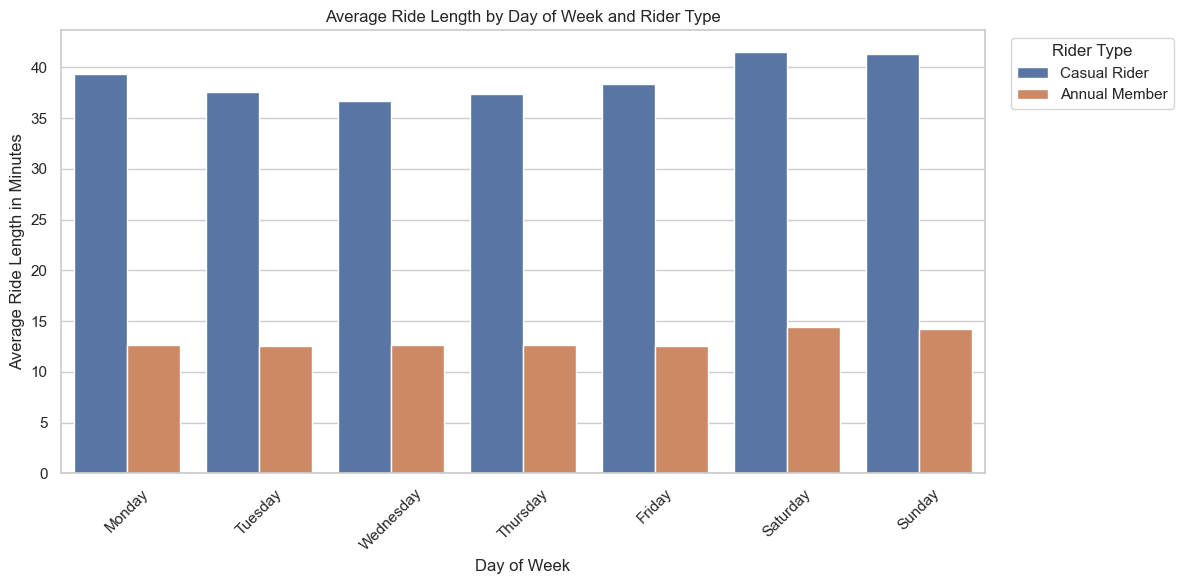

In [8]:
avg_ride = df_clean.groupby(["day_of_week","usertype"])["ride_length_minutes"].mean().reset_index()
avg_ride["day_of_week"] = pd.Categorical(avg_ride["day_of_week"], categories=day_order, ordered=True)
avg_ride = avg_ride.sort_values("day_of_week")
avg_ride["usertype"] = avg_ride["usertype"].replace({"Customer":"Casual Rider","Subscriber":"Annual Member"})
plt.figure(figsize=(12,6))
sns.barplot(data=avg_ride, x="day_of_week", y="ride_length_minutes", hue="usertype")
plt.title("Average Ride Length by Day of Week and Rider Type")
plt.xlabel("Day of Week"); plt.ylabel("Average Ride Length in Minutes")
plt.xticks(rotation=45); plt.legend(title="Rider Type", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.show()


### Weekly Usage Patterns
Ride counts compared across days of week.

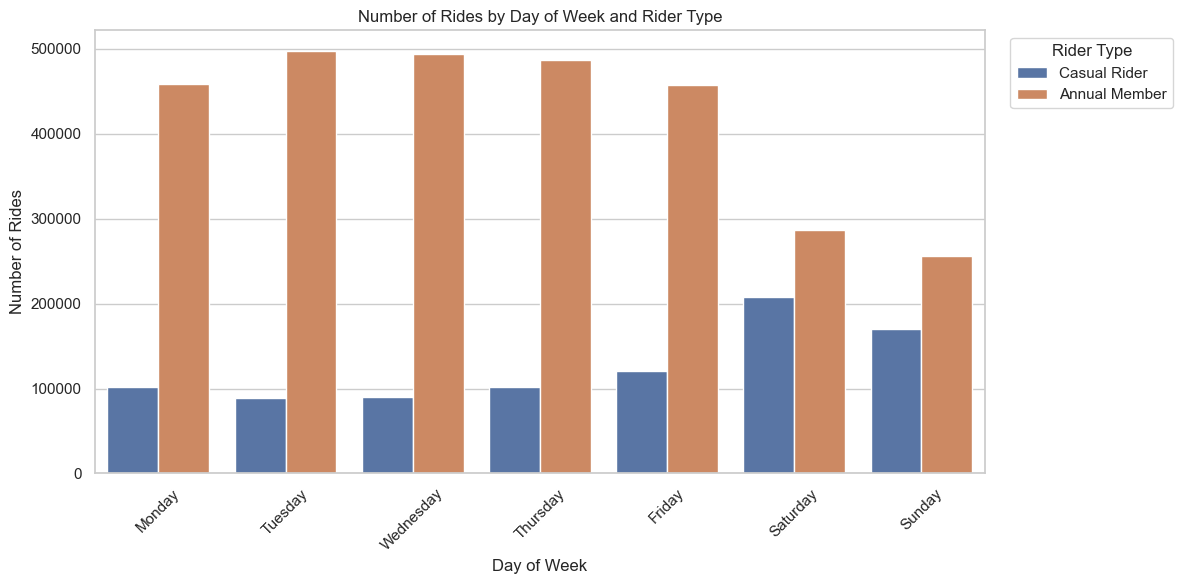

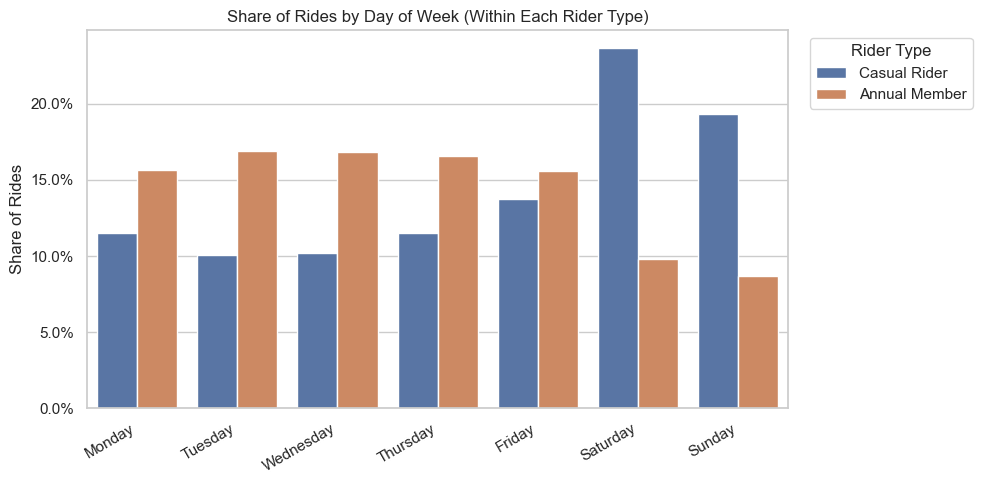

In [9]:
ride_counts = df_clean.groupby(["day_of_week","usertype"]).size().reset_index(name="number_of_rides")
ride_counts["day_of_week"] = pd.Categorical(ride_counts["day_of_week"], categories=day_order, ordered=True)
ride_counts = ride_counts.sort_values("day_of_week")
ride_counts["usertype"] = ride_counts["usertype"].replace({"Customer":"Casual Rider","Subscriber":"Annual Member"})
plt.figure(figsize=(12,6))
sns.barplot(data=ride_counts, x="day_of_week", y="number_of_rides", hue="usertype")
plt.title("Number of Rides by Day of Week and Rider Type")
plt.xlabel("Day of Week"); plt.ylabel("Number of Rides")
plt.xticks(rotation=45); plt.legend(title="Rider Type", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.show()

# Share within type - FIXED using transform not apply
dow_counts = df_clean.groupby(["usertype","day_of_week"]).size().reset_index(name="rides")
dow_counts["share_within_type"] = dow_counts["rides"] / dow_counts.groupby("usertype")["rides"].transform("sum")
dow_counts["usertype"] = dow_counts["usertype"].replace({"Customer":"Casual Rider","Subscriber":"Annual Member"})
plt.figure(figsize=(10,5))
sns.barplot(data=dow_counts, x="day_of_week", y="share_within_type", hue="usertype")
plt.title("Share of Rides by Day of Week (Within Each Rider Type)")
plt.xlabel(""); plt.ylabel("Share of Rides")
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xticks(rotation=30, ha="right"); plt.legend(title="Rider Type", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.show()


### Hourly Usage Patterns
Hourly ride patterns help show when each rider group is most active.

**Y-axis clarification:** Share of total rides WITHIN each rider type. 0.10 = 10% of that group's rides occurred in that hour.


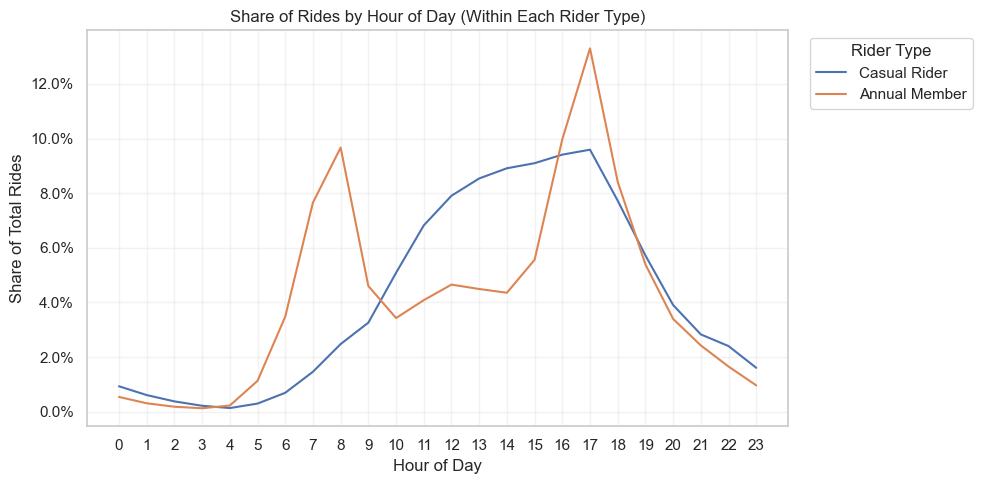

In [10]:
hour_counts = df_clean.groupby(["usertype","hour"]).size().reset_index(name="rides")
hour_counts["share"] = hour_counts["rides"] / hour_counts.groupby("usertype")["rides"].transform("sum")
hour_counts["usertype"] = hour_counts["usertype"].replace({"Customer":"Casual Rider","Subscriber":"Annual Member"})
plt.figure(figsize=(10,5))
sns.lineplot(data=hour_counts, x="hour", y="share", hue="usertype")
plt.title("Share of Rides by Hour of Day (Within Each Rider Type)")
plt.xlabel("Hour of Day"); plt.ylabel("Share of Total Rides")
plt.xticks(range(0,24)); plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.grid(True, alpha=0.25); plt.legend(title="Rider Type", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.show()


### Popular Start Stations

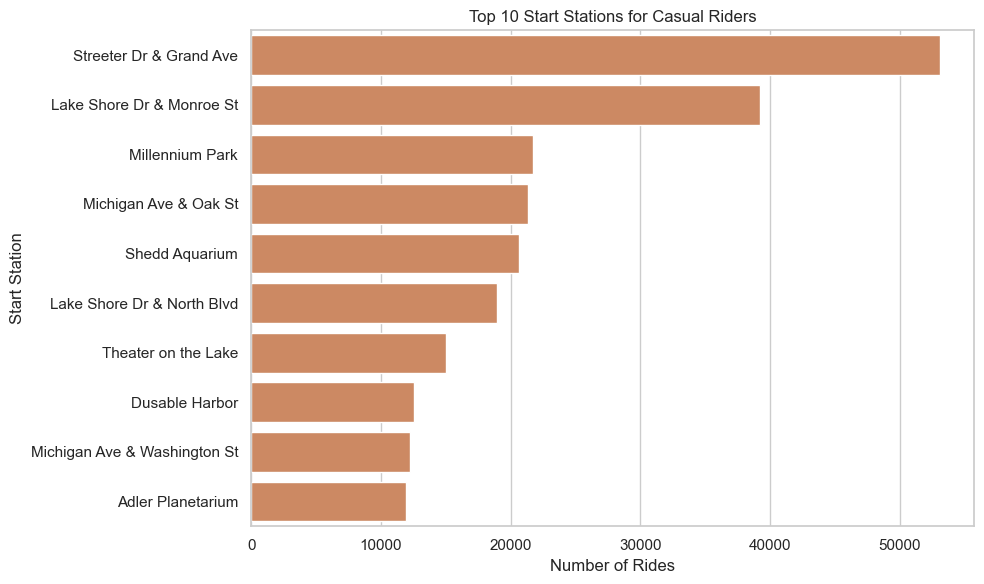

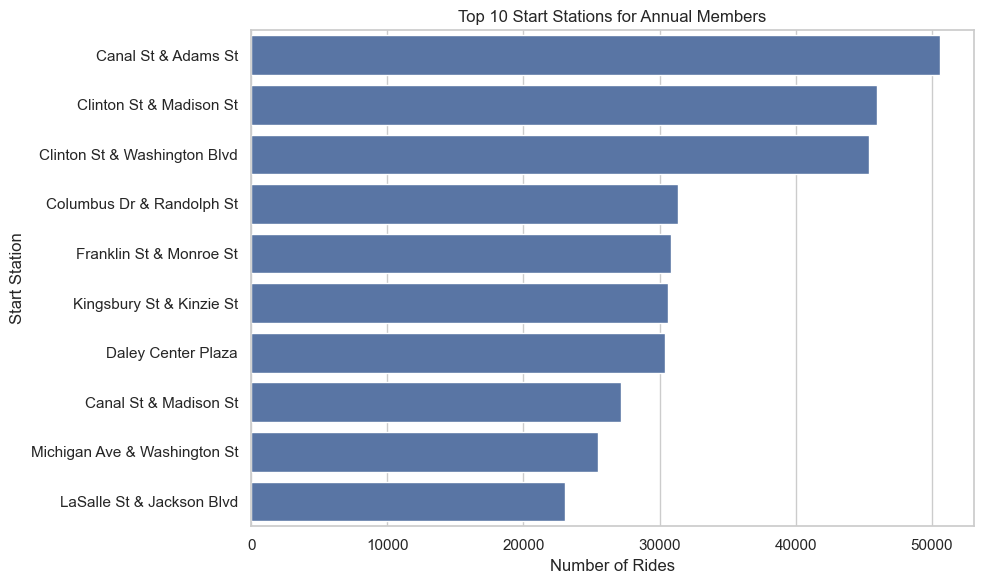

In [11]:
casual_stations = df_clean.loc[df_clean["usertype"]=="Customer","from_station_name"].value_counts().head(10).reset_index()
casual_stations.columns=["from_station_name","rides"]
plt.figure(figsize=(10,6))
sns.barplot(data=casual_stations, x="rides", y="from_station_name", color="#dd8452")
plt.title("Top 10 Start Stations for Casual Riders")
plt.xlabel("Number of Rides"); plt.ylabel("Start Station")
plt.tight_layout(); plt.show()

member_stations = df_clean.loc[df_clean["usertype"]=="Subscriber","from_station_name"].value_counts().head(10).reset_index()
member_stations.columns=["from_station_name","rides"]
plt.figure(figsize=(10,6))
sns.barplot(data=member_stations, x="rides", y="from_station_name", color="#4c72b0")
plt.title("Top 10 Start Stations for Annual Members")
plt.xlabel("Number of Rides"); plt.ylabel("Start Station")
plt.tight_layout(); plt.show()


### Key Findings
Annual members take more rides overall and are more active during weekdays and commute hours (7-9am 9.7%, 5pm 13.2%). Casual riders take longer trips (2x) and are relatively more active weekends and midday 11am-5pm (8-9.6%). Different station concentrations support leisure vs routine transportation use.


## Recommendations
- Target frequent weekend casual riders with membership campaigns emphasizing cost savings, convenience, repeat-use value.
- Promote trial at top casual stations: Streeter Dr & Grand Ave, Lake Shore Dr & Monroe, Millennium Park.
- Commuter conversion: Customers riding 7-9am should see break-even math - 5 rides/week cheaper as member.

## Conclusion
Casual riders and annual members use Cyclistic differently in ride duration, timing, weekly patterns. Annual members appear more routine transport, casual more leisure flexible. Targeted campaigns aligned to actual casual behavior can increase memberships.
